In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

modele = joblib.load("../models/churn_model.joblib")
df = pd.read_csv("../data/telco_clean.csv").drop(columns=["customerID"])

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_test.shape)

(1409, 19)


In [2]:
prep = modele.named_steps["prep"]
clf = modele.named_steps["clf"]

X_test_t = prep.transform(X_test)
if hasattr(X_test_t, "toarray"):
    X_test_t = X_test_t.toarray()

noms = prep.get_feature_names_out()
noms = [n.split("__", 1)[1] for n in noms]

X_test_df = pd.DataFrame(X_test_t, columns=noms)
print(X_test_df.shape)

(1409, 46)


In [3]:
explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_test_df)

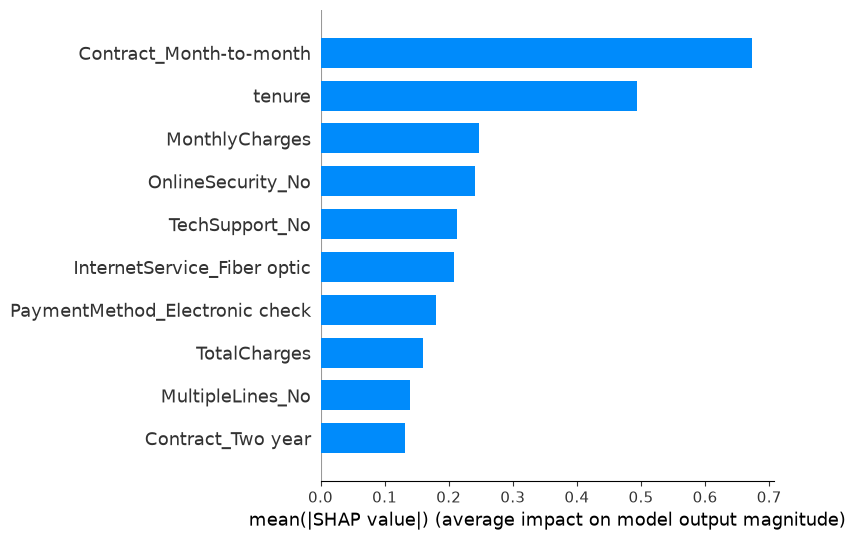

In [4]:
shap.summary_plot(shap_values, X_test_df, plot_type="bar", max_display=10)

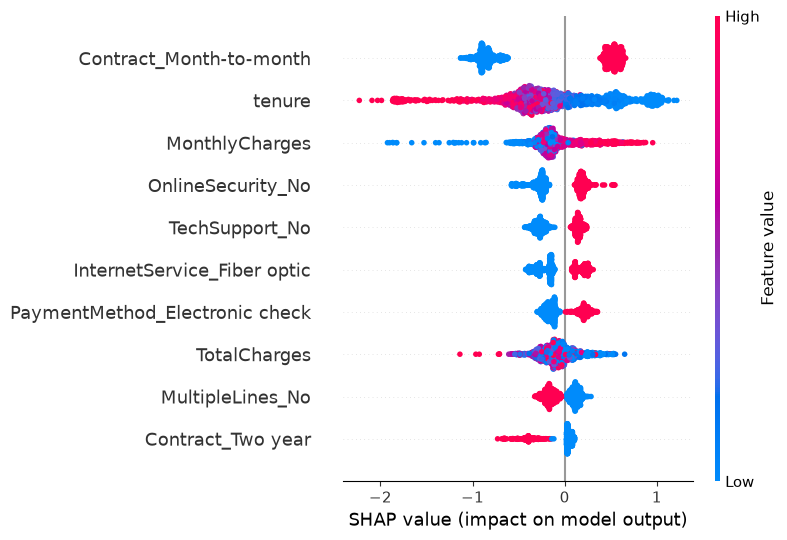

In [5]:
shap.summary_plot(shap_values, X_test_df, max_display=10)

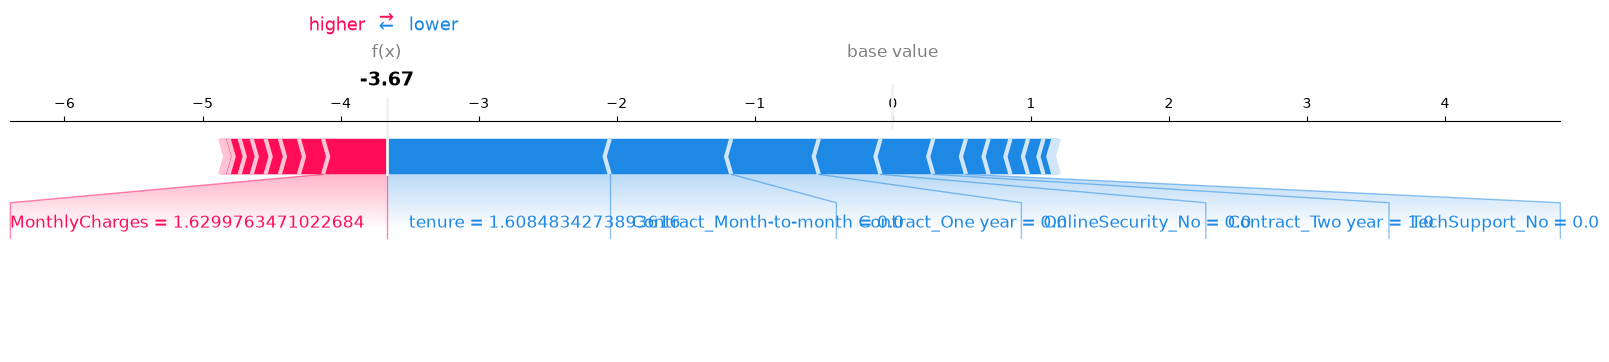

In [6]:
i = 0
shap.force_plot(
    explainer.expected_value, shap_values[i], X_test_df.iloc[i],
    matplotlib=True
)

## Interprétabilité avec SHAP
Les valeurs SHAP expliquent la contribution de chaque variable aux prédictions du modèle XGBoost.

Variables les plus influentes : contrat mensuel, ancienneté (`tenure`), charges mensuelles, absence de sécurité en ligne (`OnlineSecurity`), absence de support technique (`TechSupport`).

**Interprétation :**
- Le contrat mensuel est le premier facteur de départ, le contrat de deux ans protège fortement.
- Plus l'ancienneté est élevée, moins le client risque de partir.
- Les charges mensuelles élevées, la fibre optique et le paiement par electronic check augmentent le risque.
- Les clients sans sécurité en ligne ni support technique partent davantage, proposer ces services pourrait aider à les retenir.

Ces résultats confirment l'analyse exploratoire et ajoutent une piste d'action concrète qui est que ces services semblent jouer un rôle de fidélisation. SHAP montre une association avec le départ, pas une preuve de causalité.